# CIFAR-100 · ten seeds

Supplementary results

In [1]:
from pathlib import Path
import sys
from IPython.display import display, HTML
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'configs/cifar10.json').exists())
sys.path.insert(0,str(ROOT/'src'))
from gw import classification_report as report
config = report.read(ROOT,'cifar10')
reference = report.paper(ROOT,'s2_cifar10')
directory = ROOT/'results/cifar10/gpu_predictions'
runs,mean,sd = report.calculate(ROOT,config,directory)
from gw.publication_ui import folded_table, folded_comparison, compact_settings

## Results

Test set · 10 seeds per condition · mean ± sample SD.

In [2]:
report.show(report.table_frame(mean, sd, reference))

## Calibration

Diamonds: mean; bars: sample SD; circles: individual seeds.

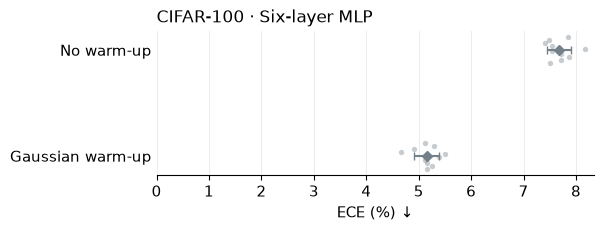

In [3]:
figure = report.plot(runs, mean, sd, ROOT / 'assets/figures/cifar10_ece.png')
display(figure)
import matplotlib.pyplot as plt
plt.close(figure)

## Reference values

Recomputed from saved checkpoint-derived test predictions.

In [4]:
check = report.comparison(mean, sd, reference)
folded_comparison(check)

## Inference

Set `RUN_INFERENCE = True` to evaluate the checkpoints.

In [5]:
from gw import cifar_inference
RUN_INFERENCE = False
if RUN_INFERENCE:
    directory=cifar_inference.run(ROOT,config,device='auto')
    runs,mean,sd=report.calculate(ROOT,config,directory)
    report.show(report.table_frame(mean,sd,reference))

## Training

Set `RUN_TRAINING = True` to train the selected seed and method. Training evaluates validation images only.

In [6]:
from gw import cifar_training
training_config=report.read(ROOT,'cifar_training')
TRAIN_SEED=20261931
TRAIN_METHOD='gaussian_scale_0p5'
RUN_TRAINING=False
if RUN_TRAINING:
    training_run=next(r for r in training_config['runs'] if r['seed']==TRAIN_SEED and r['settings']['method']==TRAIN_METHOD)
    training_output=cifar_training.run(ROOT,training_run,device='auto')
    print(training_output)

## Settings

In [7]:
import pandas as pd
settings=[]
lookup={(r['seed'],r['settings']['method']):r for r in training_config['runs']}
for r in config['runs']:
    c=lookup[(r['seed'],r['settings']['method'])]['settings']
    settings.append({'Method':r['method'],'Seed':r['seed'],'Gaussian SD':c['gaussian_scale'],'Warm-up steps':c['warmup_steps'],'Warm-up labels':c['warmup_target'],'Supervised epochs':c['epochs'],'Batch size':c['batch_size'],'Learning rate':c['lr'],'Weight decay':c['weight_decay']})
display(HTML('<details><summary>Settings</summary><div style="overflow:auto;max-height:420px">'+pd.DataFrame(settings).set_index(['Method','Seed']).to_html(border=0,na_rep='—')+'</div></details>'))
display(HTML('<details><summary>Data and model</summary>CIFAR-100 · RGB 32 × 32 · channel normalization · 8,000 training / 5,000 validation / 10,000 test images · six BP linear layers · five ReLU–BatchNorm blocks · Adam moments reset before supervised training · final-epoch checkpoint</details>'))

## Three-seed table

In [8]:
from gw.publication_ui import folded_table
config_three = report.read(ROOT, 'cifar3')
reference_three = report.paper(ROOT, 's2_cifar3')
runs_three, mean_three, sd_three = report.calculate(ROOT, config_three, ROOT/'results/cifar3/gpu_predictions')
folded_table('Three seeds', report.table_frame(mean_three, sd_three, reference_three))
folded_comparison(report.comparison(mean_three, sd_three, reference_three))
